# Tarea raster · 1. Datos, mapa base y cobertura

**Pregunta del proyecto:** ¿a quién alcanzan los incendios de octubre de 2026? Personas y
viviendas a 5 km de cada incendio en todo el Perú, con un estudio a fondo del incendio más
grande de la semana: **Río Tambo (Satipo, Junín)**, en territorio asháninka.

Este notebook cubre los pasos 1 a 3 del método del monitor del profesor:

| Paso | Qué hacemos |
|---|---|
| 1 · Descargar | Focos VIIRS (3 satélites), límites distritales, población, viviendas |
| 2 · Mapa base | Distritos y relieve (Copernicus DEM) |
| 3 · Cobertura | ESA WorldCover: bosque, pastizal o cultivo |

In [1]:
import sys, warnings
sys.path.insert(0, "..") if "src_nb" in __import__("os").getcwd() else None
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import requests

from comun import RAW, PROC, FIG, CORTE, STAC, leer_distritos

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## Paso 1 · Descargar

Todo es público y sin clave. Cada archivo se baja una sola vez; si ya existe, se reutiliza.

| Dato | Fuente | Tipo |
|---|---|---|
| Focos de calor 7 días (S-NPP, NOAA-20, NOAA-21) | NASA FIRMS, CSV «South America 7d» | Puntos |
| Límites distritales con UBIGEO | GitHub `juaneladio/peru-geojson` (INEI) | Polígonos |
| Población 2020, 1 km | WorldPop, *unconstrained*, Perú | Raster |
| Edificaciones | Google Open Buildings v3, celda S2 `911` (selva central) | Puntos |
| Relieve y cobertura | Planetary Computer: `cop-dem-glo-30`, `esa-worldcover` | Raster (se leen en línea) |

In [2]:
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/active_fire"
DESCARGAS = {
    f"firms_viirs_snpp_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    f"firms_viirs_noaa-20_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    f"firms_viirs_noaa-21_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
    "peru_distrital_simple.geojson": "https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_distrital_simple.geojson",
    "worldpop_per_2020_1km.tif": "https://data.worldpop.org/GIS/Population/Global_2000_2020_1km/2020/PER/per_ppp_2020_1km_Aggregated.tif",
    "open_buildings_v3_points_911.csv.gz": "https://storage.googleapis.com/open-buildings-data/v3/points_s2_level_4_gzip/911_buildings.csv.gz",
}

for nombre, url in DESCARGAS.items():
    destino = RAW / nombre
    if not destino.exists():
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(destino, "wb") as fh:
                for trozo in r.iter_content(1 << 20):
                    fh.write(trozo)
    print(f"{destino.stat().st_size / 1e6:8.1f} MB  {nombre}")

     4.9 MB  firms_viirs_snpp_sudamerica_7d_2026-10-21.csv
     5.2 MB  firms_viirs_noaa-20_sudamerica_7d_2026-10-21.csv
     5.0 MB  firms_viirs_noaa-21_sudamerica_7d_2026-10-21.csv
     1.9 MB  peru_distrital_simple.geojson
     7.4 MB  worldpop_per_2020_1km.tif
   187.6 MB  open_buildings_v3_points_911.csv.gz


## Paso 2 · Mapa base

1 834 distritos con su UBIGEO. Ubicamos Río Tambo, el distrito más extenso de Junín.

In [3]:
distritos = leer_distritos()
rio_tambo = distritos[distritos.NOMBDIST == "RIO TAMBO"]
area_km2 = rio_tambo.to_crs(32718).area.iloc[0] / 1e6
print(f"{len(distritos):,} distritos · Río Tambo: UBIGEO {rio_tambo.IDDIST.iloc[0]}, {area_km2:,.0f} km²")

1,834 distritos · Río Tambo: UBIGEO 120608, 10,223 km²


El relieve viene del modelo Copernicus DEM. Lo leemos **solo en la caja de Río Tambo** y a
resolución reducida (vista general del COG): no hace falta bajar el raster nacional a 30 m
para un mapa base.

In [4]:
import rioxarray
from rioxarray.merge import merge_arrays

catalogo = pystac_client.Client.open(STAC, modifier=planetary_computer.sign_inplace)
caja = rio_tambo.total_bounds


def mosaico(coleccion, activo, nivel, caja=caja):
    """Lee y une las teselas de una colección de Planetary Computer recortadas a la caja."""
    items = catalogo.search(collections=[coleccion], bbox=list(caja)).item_collection()
    piezas = [rioxarray.open_rasterio(it.assets[activo].href, overview_level=nivel)
              .rio.clip_box(*caja) for it in items]
    return merge_arrays(piezas).squeeze()


dem = mosaico("cop-dem-glo-30", "data", nivel=2)          # ~240 m por píxel
dem = dem.where(dem > -100)
print(f"DEM: {dem.shape}, altitud {float(dem.min()):,.0f}–{float(dem.max()):,.0f} m")

DEM: (745, 604), altitud 0–4,850 m


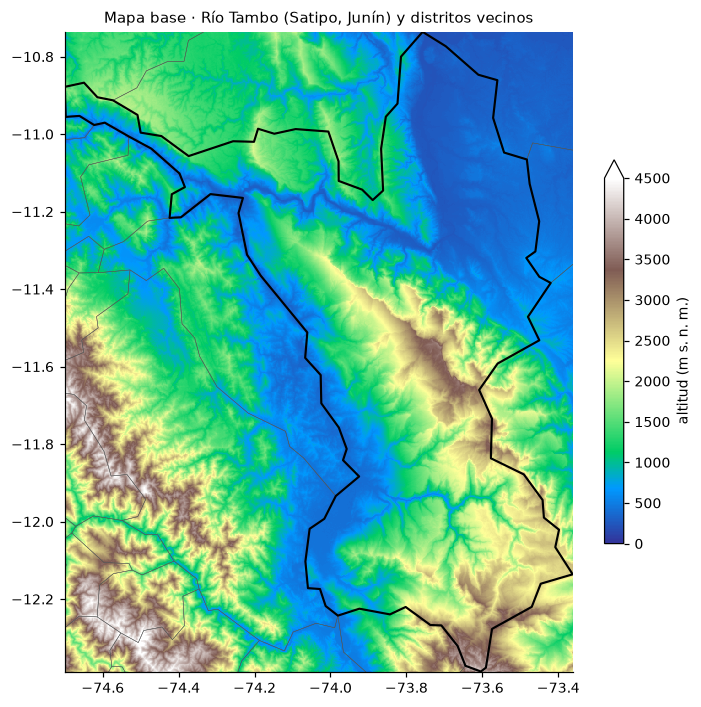

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
dem.plot.imshow(ax=ax, cmap="terrain", vmin=0, vmax=4500,
                cbar_kwargs={"label": "altitud (m s. n. m.)", "shrink": 0.6})
distritos.boundary.plot(ax=ax, color="#555", linewidth=0.3)
rio_tambo.boundary.plot(ax=ax, color="black", linewidth=1.4)
ax.set_xlim(caja[0], caja[2]); ax.set_ylim(caja[1], caja[3])
ax.set_title("Mapa base · Río Tambo (Satipo, Junín) y distritos vecinos", fontsize=10)
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); fig.savefig(FIG / "01_mapa_base_rio_tambo.png", dpi=150); plt.show()

Río Tambo baja de los Andes (más de 4 000 m) hasta la selva baja del río Tambo (unos 300 m).
Esa gradiente es también un gradiente de ocupación: colonos en las partes altas y valles,
comunidades nativas asháninka a lo largo de los ríos Ene y Tambo.

## Paso 3 · Cobertura del suelo

ESA WorldCover 2021 (10 m). En el mapa base usamos una vista general (~80 m); el cruce fino
con el área quemada se hace a 10 m en el notebook 3.

In [6]:
CLASES_WC = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Urbano",
             60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar", 100: "Musgo"}

wc = mosaico("esa-worldcover", "map", nivel=2)
dist_wc = (pd.Series(wc.values.ravel()).value_counts(normalize=True)
           .rename(index=CLASES_WC).drop(index=0, errors="ignore"))
print("Cobertura en la caja de Río Tambo:")
print((dist_wc * 100).round(1).head(6).to_string())

Cobertura en la caja de Río Tambo:
Bosque           90.4
Pastizal          8.5
Agua              0.6
Matorral          0.3
Suelo desnudo     0.1
Urbano            0.1


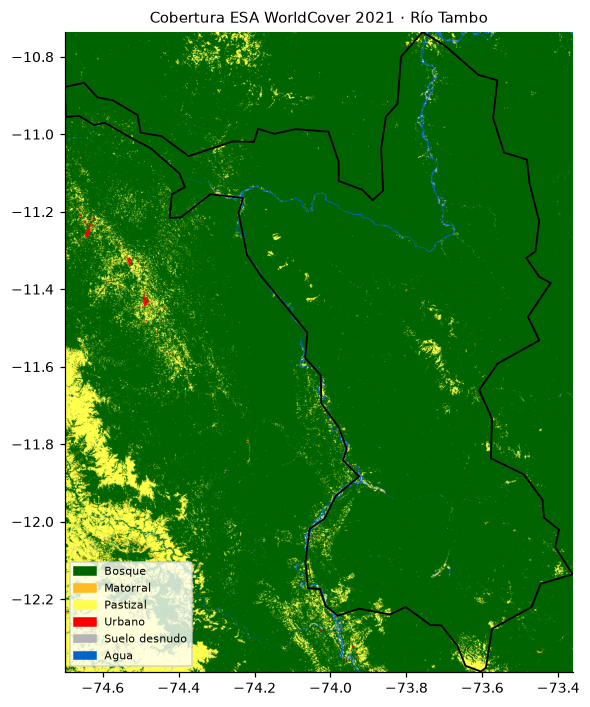

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
colores = ["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4",
           "#f0f0f0", "#0064c8", "#0096a0", "#00cf75", "#fae6a0"]
codigos = list(CLASES_WC)
cmap = ListedColormap(colores); norm = BoundaryNorm(codigos + [101], cmap.N)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(wc.where(wc > 0).values, cmap=cmap, norm=norm,
          extent=[float(wc.x.min()), float(wc.x.max()), float(wc.y.min()), float(wc.y.max())])
rio_tambo.boundary.plot(ax=ax, color="black", linewidth=1.2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=CLASES_WC[k]) for k, c in zip(codigos, colores)
                   if CLASES_WC[k] in dist_wc.index[:6]], loc="lower left", fontsize=7, frameon=True)
ax.set_title("Cobertura ESA WorldCover 2021 · Río Tambo", fontsize=10)
plt.tight_layout(); fig.savefig(FIG / "01_cobertura_rio_tambo.png", dpi=150); plt.show()